<a href="https://colab.research.google.com/github/SJ174/MLCW/blob/main/MLCW_Task_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

## 1. Dataset Structure and Data Types

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Number of customers:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of customers: 7043
Number of columns: 21


In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
(df['TotalCharges'].astype(str).str.strip() == '').sum()

np.int64(11)

## 2. Data Quality and Missing Value Investigation

In [11]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [12]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [13]:
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


The initial inspection identified no missing values using pandas' standard null-value check. However, further investigation revealed 11 empty strings in the TotalCharges column. The column was initially stored as an object data type, so the values were converted to a numerical format using pd.to_numeric(). The empty strings were then represented as missing numerical values (NaN), allowing them to be identified through a standard missing-value check. No completely duplicated rows were detected in the dataset.

Further examination revealed that all 11 affected customers had a tenure of zero months and a churn status of "No". This suggests that these customers were new subscribers for whom total charges had not yet been recorded. However, this explanation cannot be confirmed from the dataset alone.

## 3. Exploratory Analysis of Customer Churn

In [14]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [15]:
churn_counts = df['Churn'].value_counts()
churn_percentages = df['Churn'].value_counts(normalize=True) * 100

print("Customer counts:")
print(churn_counts)

print("\nCustomer percentages:")
print(churn_percentages.round(2))

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


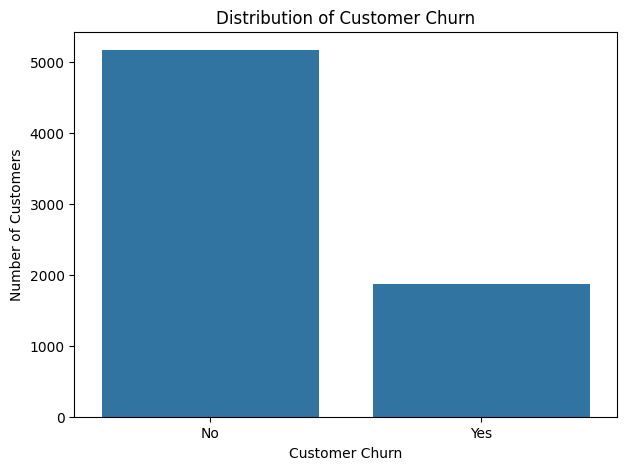

In [16]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Churn')

plt.title('Distribution of Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()

The dataset contains 7,043 customer records, of which 5,174 customers (73.46%) remained with the company, while 1,869 customers (26.54%) churned. The bar chart illustrates the distribution of the target variable, Churn. It shows that the majority of customers remained with the company, while approximately one-quarter discontinued their services.

The difference between the two categories indicates that the target variable is imbalanced, with the non-churn category containing more observations than the churn category. This is an important consideration when developing and evaluating machine learning classification models, as accuracy alone may not reflect a model's ability to identify customers who churn. Therefore, additional evaluation metrics, such as precision, recall, F1-score, and the confusion matrix, should be considered when assessing model performance.

This analysis establishes the baseline distribution of customer churn and provides a foundation for investigating relationships between customer characteristics and churn in subsequent analyses.

## 4. Relationship Between Customer Tenure and Churn

In [17]:
df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


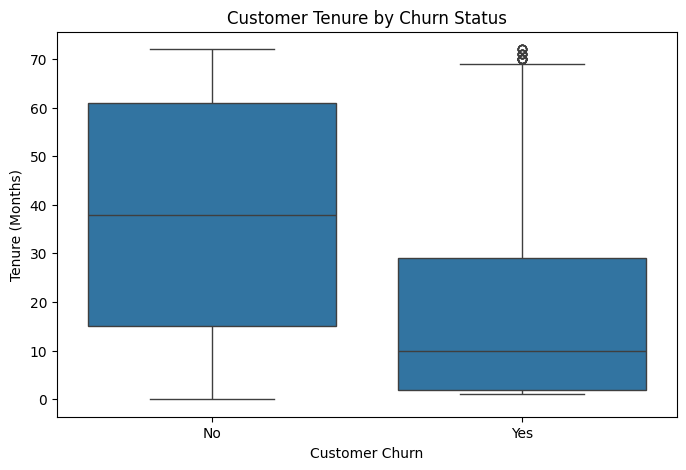

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Tenure (Months)')

plt.show()

The relationship between customer tenure and churn was investigated using descriptive statistics and a box plot. Customers who remained with the company had a mean tenure of
37.57 months and a median tenure of 38 months. In comparison, customers who churned had a mean tenure of 17.98 months and a median tenure of 10 months.

The box plot further displays this difference, with the median tenure of customers who churned considerably lower than that of customers who stayed. The middle 50% of churned customers had tenures between 2 and 29 months, whereas the corresponding range for customers who remained was between 15 and 61 months.

These findings suggest an association between shorter customer tenure and churn. However, the distributions overlap, indicating that tenure alone cannot completely distinguish customers who churn from those who remain. Several potential outliers were also observed among customers who churned, representing individuals with relatively long tenures. Overall, tenure appears to be a potentially useful feature for predicting customer churn.

## 5. Relationship Between Contract Type and Churn

In [19]:
df['Contract'].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


In [20]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


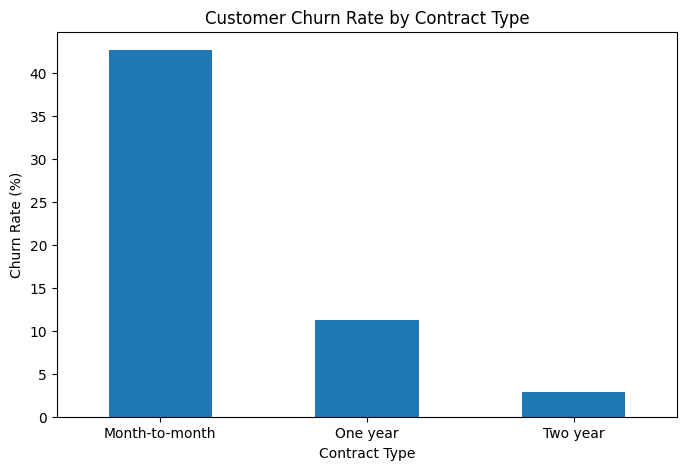

In [21]:
contract_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The relationship between contract type and customer churn was investigated by calculating the churn rate for each contract category and visualising the results using a bar chart. The results show that customers with month-to-month contracts had the highest churn rate, at 42.71%. In comparison, customers with one-year contracts had a churn rate of 11.27%, while those with two-year contracts had the lowest churn rate of 2.83%.

These findings indicate a substantial difference in churn rates across contract types. Customers with month-to-month contracts were considerably more likely to churn than customers with longer-term contracts in this dataset. The results suggest that contract type may be an important feature for predicting customer churn.

From a business perspective, these findings could help the company identify customer groups that may benefit from targeted retention strategies. However, the analysis establishes an association rather than causation. Other factors, such as customer tenure, pricing and service experiences, may also contribute to the observed differences.